# Tugas Digital Image Processing — Histogram Equalization

4 kasus: `low_contrast`, `underexposed` (sesuai penerapan HE), `blur`, `oversharp` (tidak sesuai)


## Import & Mount Drive

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
import os
from google.colab import drive

drive.mount('/content/drive')

Mounted at /content/drive


## Load Dataset


In [2]:
DATASET_DIR = "/content/drive/MyDrive/Notebook/PCD_Assignment02/"
CASES = ["low_contrast", "underexposed", "blur", "oversharp"]

files = os.listdir(DATASET_DIR)
filenames = [next(f for f in files if c in f.lower()) for c in CASES]
images = [np.array(Image.open(os.path.join(DATASET_DIR, f)).convert("L")) for f in filenames]

filenames

['low_contrast.jpg', 'underexposed.jpg', 'blur.jpg', 'oversharp.jpg']

## Histogram Awal

`low_contrast` & `underexposed` cocok untuk HE. `blur` & `oversharp` tidak cocok (bukan masalah distribusi intensitas pixel).


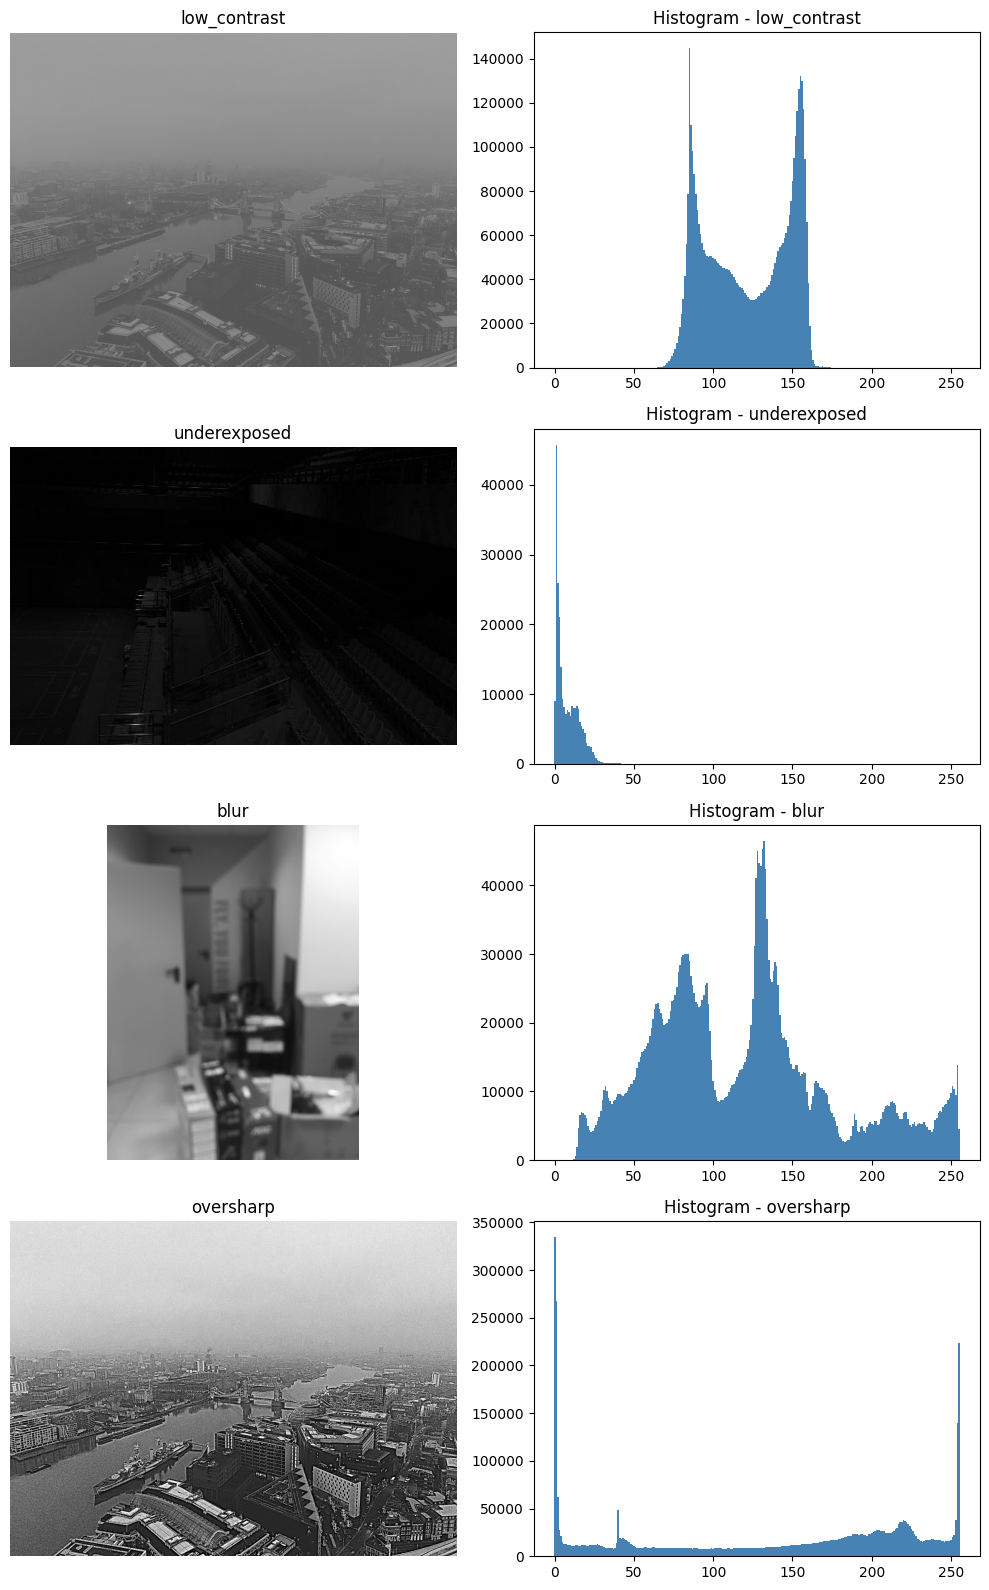

In [3]:
def compute_histogram(img):
    hist = np.zeros(256, dtype=int)
    for v in img.flatten():
        hist[v] += 1
    return hist

fig, axes = plt.subplots(len(images), 2, figsize=(10, 4 * len(images)))
for i, (img, case) in enumerate(zip(images, CASES)):
    hist = compute_histogram(img)
    axes[i, 0].imshow(img, cmap="gray", vmin=0, vmax=255)
    axes[i, 0].set_title(case)
    axes[i, 0].axis("off")
    axes[i, 1].bar(range(256), hist, color="steelblue", width=1)
    axes[i, 1].set_title(f"Histogram - {case}")
plt.tight_layout()
plt.show()

## Histogram Equalization

$$p(r_k)=\frac{n_k}{M \times N} \qquad cdf(r_k)=\sum_{j=0}^{k} p(r_j) \qquad s_k = round[(L-1)\cdot cdf(r_k)]$$


In [4]:
def compute_cdf(hist, total):
    pdf = hist / total
    cdf = np.zeros_like(pdf)
    running = 0.0
    for k in range(256):
        running += pdf[k]
        cdf[k] = running
    return cdf

def histogram_equalization(img):
    M, N = img.shape
    hist = compute_histogram(img)
    cdf = compute_cdf(hist, M * N)
    tmap = np.round(255 * cdf).astype(np.uint8)
    out = np.zeros_like(img)
    for i in range(M):
        for j in range(N):
            out[i, j] = tmap[img[i, j]]
    return out, hist, cdf

In [5]:
results = []
for img, case, name in zip(images, CASES, filenames):
    eq, hist, cdf = histogram_equalization(img)
    results.append({"case": case, "filename": name, "original": img, "equalized": eq, "hist": hist})

## Hasil

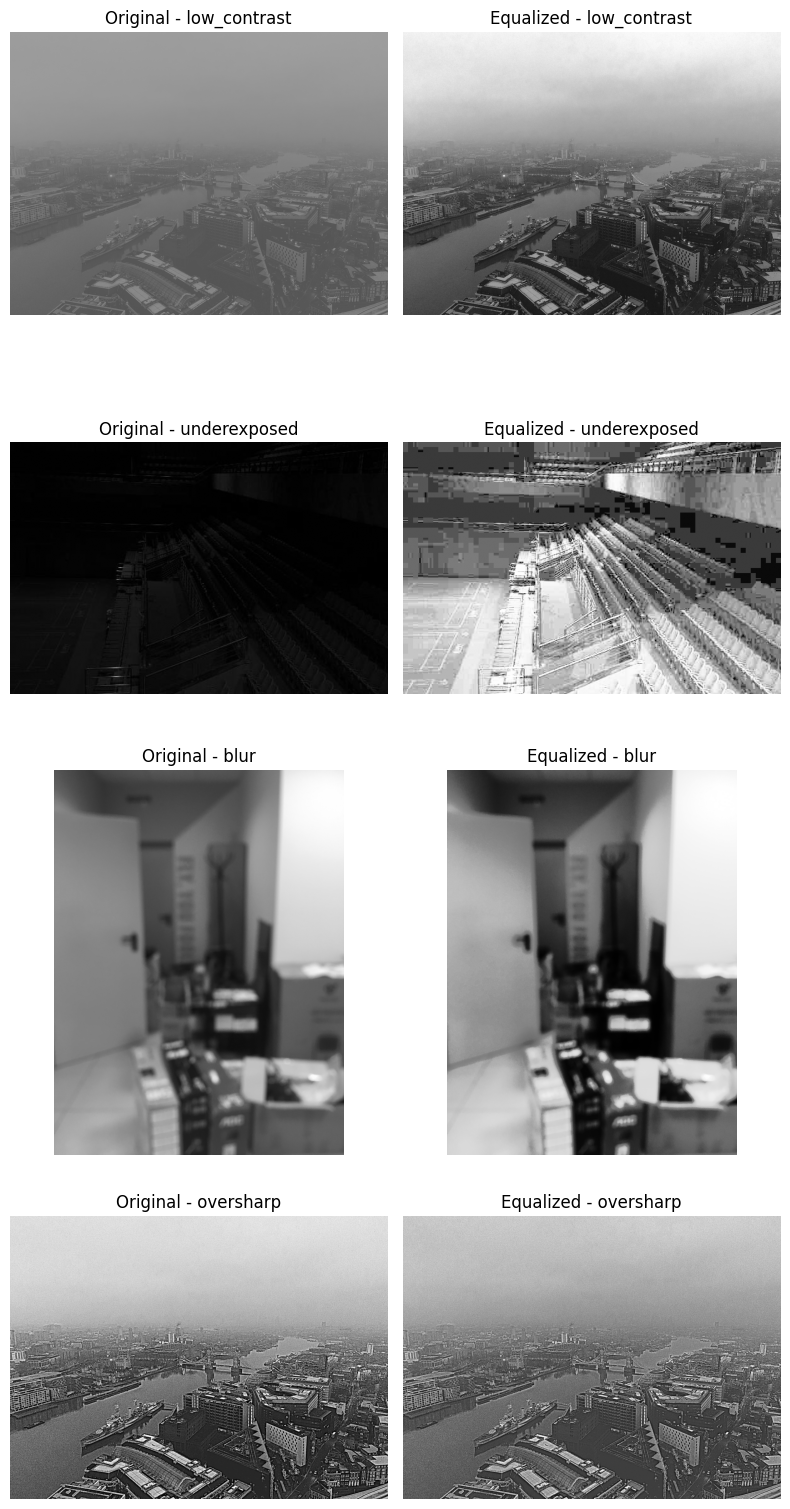

In [6]:
fig, axes = plt.subplots(len(results), 2, figsize=(8, 4 * len(results)))
for i, res in enumerate(results):
    axes[i, 0].imshow(res["original"], cmap="gray", vmin=0, vmax=255)
    axes[i, 0].set_title(f"Original - {res['case']}")
    axes[i, 0].axis("off")
    axes[i, 1].imshow(res["equalized"], cmap="gray", vmin=0, vmax=255)
    axes[i, 1].set_title(f"Equalized - {res['case']}")
    axes[i, 1].axis("off")
plt.tight_layout()
plt.show()

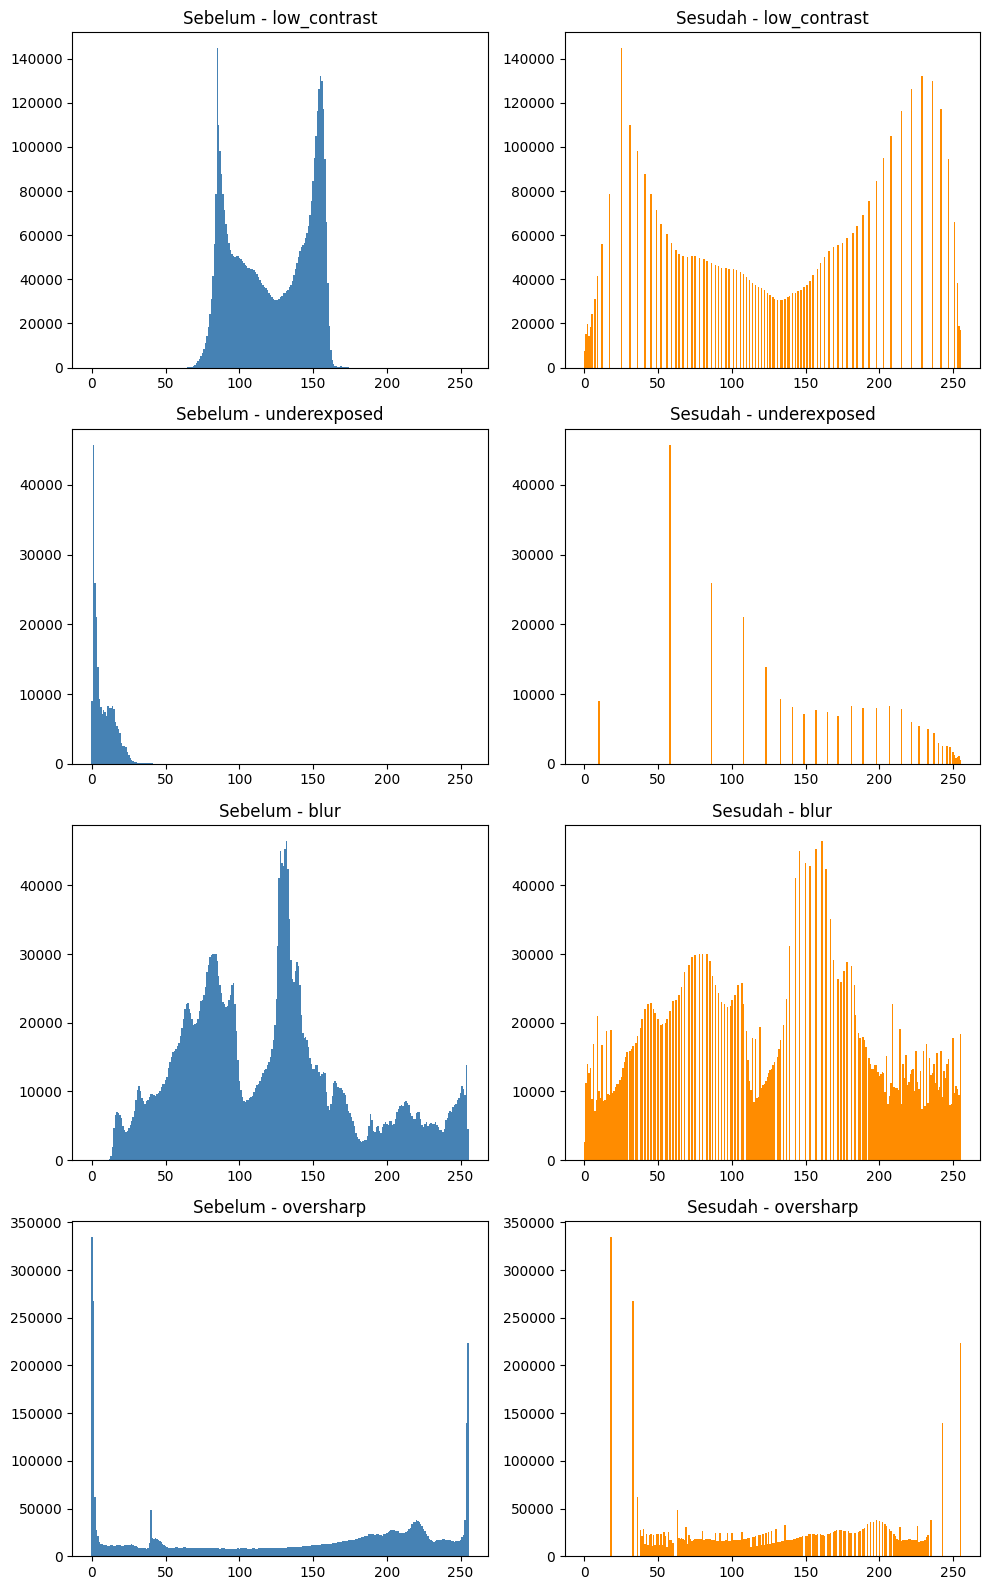

In [7]:
fig, axes = plt.subplots(len(results), 2, figsize=(10, 4 * len(results)))
for i, res in enumerate(results):
    hist_eq = compute_histogram(res["equalized"])
    axes[i, 0].bar(range(256), res["hist"], color="steelblue", width=1)
    axes[i, 0].set_title(f"Sebelum - {res['case']}")
    axes[i, 1].bar(range(256), hist_eq, color="darkorange", width=1)
    axes[i, 1].set_title(f"Sesudah - {res['case']}")
plt.tight_layout()
plt.show()

## Simpan Hasil Equalization ke Drive


In [8]:
OUTPUT_DIR = os.path.join(DATASET_DIR, "equalized")
os.makedirs(OUTPUT_DIR, exist_ok=True)

for res in results:
    out_path = os.path.join(OUTPUT_DIR, f"{res['case']}_equalized.jpg")
    Image.fromarray(res["equalized"]).save(out_path)
    print(f"Saved: {out_path}")

Saved: /content/drive/MyDrive/Notebook/PCD_Assignment02/equalized/low_contrast_equalized.jpg
Saved: /content/drive/MyDrive/Notebook/PCD_Assignment02/equalized/underexposed_equalized.jpg
Saved: /content/drive/MyDrive/Notebook/PCD_Assignment02/equalized/blur_equalized.jpg
Saved: /content/drive/MyDrive/Notebook/PCD_Assignment02/equalized/oversharp_equalized.jpg


## Evaluasi


In [9]:
def mean_val(img):
    return np.sum(img.astype(float)) / img.size

def std_val(img):
    m = mean_val(img)
    return np.sqrt(np.sum((img.astype(float) - m) ** 2) / img.size)

header = f"{'Kasus':<15}{'Mean Awal':<12}{'Mean Akhir':<12}{'Std Awal':<12}{'Std Akhir':<12}"
print(header)
print("-" * len(header))
for res in results:
    mean_o, mean_e = mean_val(res["original"]), mean_val(res["equalized"])
    std_o, std_e = std_val(res["original"]), std_val(res["equalized"])
    print(f"{res['case']:<15}{mean_o:<12.2f}{mean_e:<12.2f}{std_o:<12.2f}{std_e:<12.2f}")

Kasus          Mean Awal   Mean Akhir  Std Awal    Std Akhir   
---------------------------------------------------------------
low_contrast   121.83      129.39      26.99       73.86       
underexposed   7.71        137.04      7.50        66.86       
blur           118.98      128.30      56.63       73.55       
oversharp      136.18      129.40      90.99       72.76       
